In [101]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

In [102]:
arm_length = 600 # mm
support_x = -40 # mm
support_y = 80 # mm

spring_dist = 280 # mm from root to spring mount

initial_spring_force = 3 # N

end_weight = 6 # N

Spring rate: 0.4
Spring rest length initial: 203.9607805437114
Spring max length: 329.84845004941286
Length offset: 0
Max joint torque: 233.32126370746914


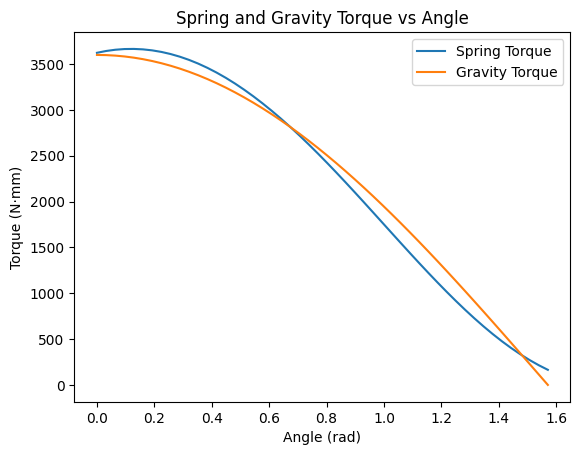

In [103]:
spring_rest_length_initial = np.sqrt(
    (spring_dist * np.cos(np.pi/2) - support_x)**2 +
    (spring_dist * np.sin(np.pi/2) - support_y)**2
    ) # mm

spring_max_length = np.sqrt(
    (spring_dist * np.cos(0) - support_x)**2 +
    (spring_dist * np.sin(0) - support_y)**2
    ) # mm

def calculate_spring_torque(spring_rate, length_offset):
    spring_rest_length = spring_rest_length_initial + length_offset # mm

    angles = np.linspace(0, np.pi/2)

    gravity_torque = arm_length * np.cos(angles) * end_weight

    f_dx = spring_dist * np.cos(angles) - support_x
    f_dy = spring_dist * np.sin(angles) - support_y
    spring_force = -spring_rate * (np.sqrt(f_dx**2 + f_dy**2) - spring_rest_length) - initial_spring_force

    fx = f_dx / np.sqrt(f_dx**2 + f_dy**2) * spring_force
    fy = f_dy / np.sqrt(f_dx**2 + f_dy**2) * spring_force

    dx = spring_dist * np.cos(angles)
    dy = spring_dist * np.sin(angles)

    spring_torque = dx * fy - dy * fx

    return angles, spring_torque, gravity_torque

def get_spring_error(params):
    spring_rate, length_offset = params
    angles, spring_torque, gravity_torque = calculate_spring_torque(spring_rate, length_offset)
    
    return np.max(abs(spring_torque - gravity_torque))*0.2 + np.sum(np.abs(spring_torque - gravity_torque)*np.diff(angles)[0])

# spring_rate, length_offset = least_squares(get_spring_error, (0.5, 0)).x
spring_rate = 0.2*2
length_offset = 0
print("Spring rate:", spring_rate)
print("Spring rest length initial:", spring_rest_length_initial)
print("Spring max length:", spring_max_length)
print("Length offset:", length_offset)



angles, spring_torque, gravity_torque = calculate_spring_torque(spring_rate, length_offset)
print("Max joint torque:", np.max(abs(spring_torque - gravity_torque)))

fig, ax = plt.subplots()
ax.plot(angles, spring_torque, label='Spring Torque')
ax.plot(angles, gravity_torque, label='Gravity Torque')
ax.set_xlabel('Angle (rad)')
ax.set_ylabel('Torque (N·mm)')
ax.set_title('Spring and Gravity Torque vs Angle')
ax.legend()
plt.show()